# Stock Price Forecasting: ARIMA vs. Gradient Boosting

Prototype of the forecasting engine: predicts the 5-day return of a stock with two models and compares them against a naive baseline.

> ⚠️ **Not investment advice.**

## 1. Configuration

Imports libraries and sets parameters: `TICKERS` (stocks), `HORIZON` (days ahead), `N_TEST` (backtest length), `REFIT_EVERY` (re-train interval), `ARIMA_WINDOW` (ARIMA history) and `ALPHA` (0.2 = 80% interval).

In [1]:
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yfinance as yf
from sklearn.ensemble import HistGradientBoostingRegressor
from statsmodels.tsa.arima.model import ARIMA

# statsmodels prints many convergence warnings when searching ARIMA orders.
# They are harmless here and would hide the useful output.
warnings.filterwarnings("ignore")

# Show numbers with 4 decimals in tables and use a wide default figure size.
pd.set_option("display.float_format", "{:.4f}".format)
plt.rcParams["figure.figsize"] = (12, 4)

# --- Experiment parameters -----------------------------------------------------------
TICKERS = ["AAPL", "MSFT", "NOKIA.HE"]  # Helsinki-listed stocks use the .HE suffix
START = "2015-01-01"  # first date of downloaded history
HORIZON = 5           # forecast horizon in trading days (5 ≈ one calendar week)
N_TEST = 500          # number of backtest forecast days (~2 years of trading days)
REFIT_EVERY = 20      # models are re-trained every 20 trading days (~1 month)
ARIMA_WINDOW = 750    # ARIMA is fit on the most recent 750 days (~3 years)
ALPHA = 0.2           # 1 - ALPHA = 80% prediction interval

# --- Paths ---------------------------------------------------------------------------
# The notebook lives in notebooks/, but data is stored in <project>/data/.
# This works both when the notebook is run from notebooks/ and from the project root.
PROJECT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = PROJECT_DIR / "data"
DATA_DIR.mkdir(exist_ok=True)  # create the folder if it does not exist yet

## 2. Data Loading

Downloads adjusted daily prices (OHLCV) from Yahoo Finance and caches them in `data/<ticker>.csv`. Use `force=True` to re-download.

In [2]:
def load_data(ticker: str, start: str = START, force: bool = False) -> pd.DataFrame:
    """Return daily OHLCV data for `ticker`. Uses the local cache if it was saved today."""
    path = DATA_DIR / f"{ticker}.csv"

    # 1) Use the cached file if it exists and was written today.
    if path.exists() and not force:
        modified = pd.Timestamp(path.stat().st_mtime, unit="s").date()  # file modification date
        if modified == pd.Timestamp.today().date():
            # index_col=0 -> the first column (Date) becomes the row index
            # parse_dates=True -> the index is converted to real datetime objects
            return pd.read_csv(path, index_col=0, parse_dates=True)

    # 2) Otherwise download from Yahoo Finance.
    df = yf.download(ticker, start=start, auto_adjust=True, progress=False)
    if df.empty:
        raise ValueError(f"No data for ticker {ticker}. Check the symbol and your connection.")

    # yfinance returns two-level column names such as ("Close", "AAPL").
    # We only download one ticker at a time, so we keep just the first level ("Close").
    if isinstance(df.columns, pd.MultiIndex):
        df.columns = df.columns.get_level_values(0)

    # Keep only the columns we need and drop rows with missing values.
    df = df[["Open", "High", "Low", "Close", "Volume"]].dropna()
    df.index.name = "Date"

    # 3) Save to the cache for the next run.
    df.to_csv(path)
    return df


# Load every ticker into a dictionary: {"AAPL": DataFrame, "MSFT": DataFrame, ...}
data = {}
for t in TICKERS:
    data[t] = load_data(t)
    d = data[t]
    # Quick sanity check: number of rows, date range and missing values.
    print(f"{t:10s} {len(d):5d} rows  {d.index[0].date()} – {d.index[-1].date()}  "
          f"missing values: {int(d.isna().sum().sum())}")

AAPL        2980 rows  2015-01-02 – 2026-11-06  missing values: 0
MSFT        2980 rows  2015-01-02 – 2026-11-06  missing values: 0
NOKIA.HE    2980 rows  2015-01-02 – 2026-11-09  missing values: 0


Last rows of the raw data:

In [3]:
data[TICKERS[0]].tail()

,Open,High,Low,Close,Volume
Date,,,,,
2026-11-02,342.6700,343.8000,335.8200,338.3200,64757700
2026-11-03,325.5800,334.5000,325.3300,331.9000,63160000
2026-11-04,341.5700,354.5000,340.9900,349.5100,89637700
2026-11-05,353.8900,355.3800,342.0600,344.1700,75678900
2026-11-06,338.7300,345.7900,338.3000,342.3700,44676300


## 3. Exploratory Analysis

Plots rebased prices, moving averages and the distribution of daily returns (volatility).

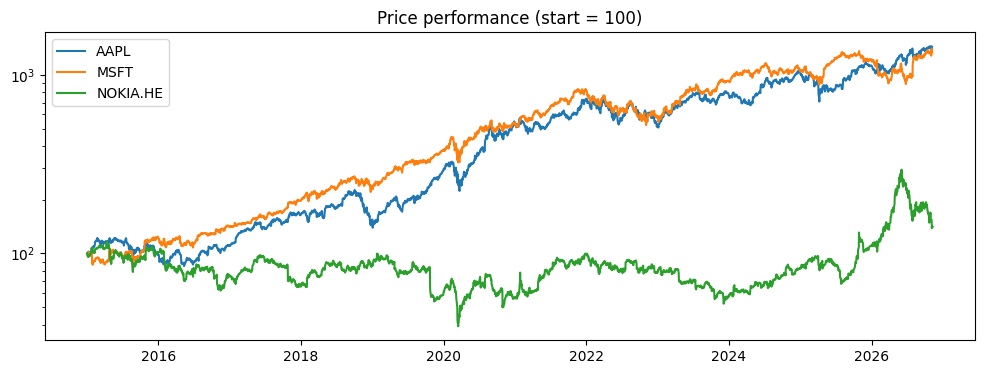

In [4]:
fig, ax = plt.subplots()
for t, d in data.items():
    # Rebase: divide every price by the first price and multiply by 100.
    ax.plot(d.index, d["Close"] / d["Close"].iloc[0] * 100, label=t)
ax.set_title("Price performance (start = 100)")
ax.set_yscale("log")  # log scale: equal distances = equal percentage changes
ax.legend()
plt.show()

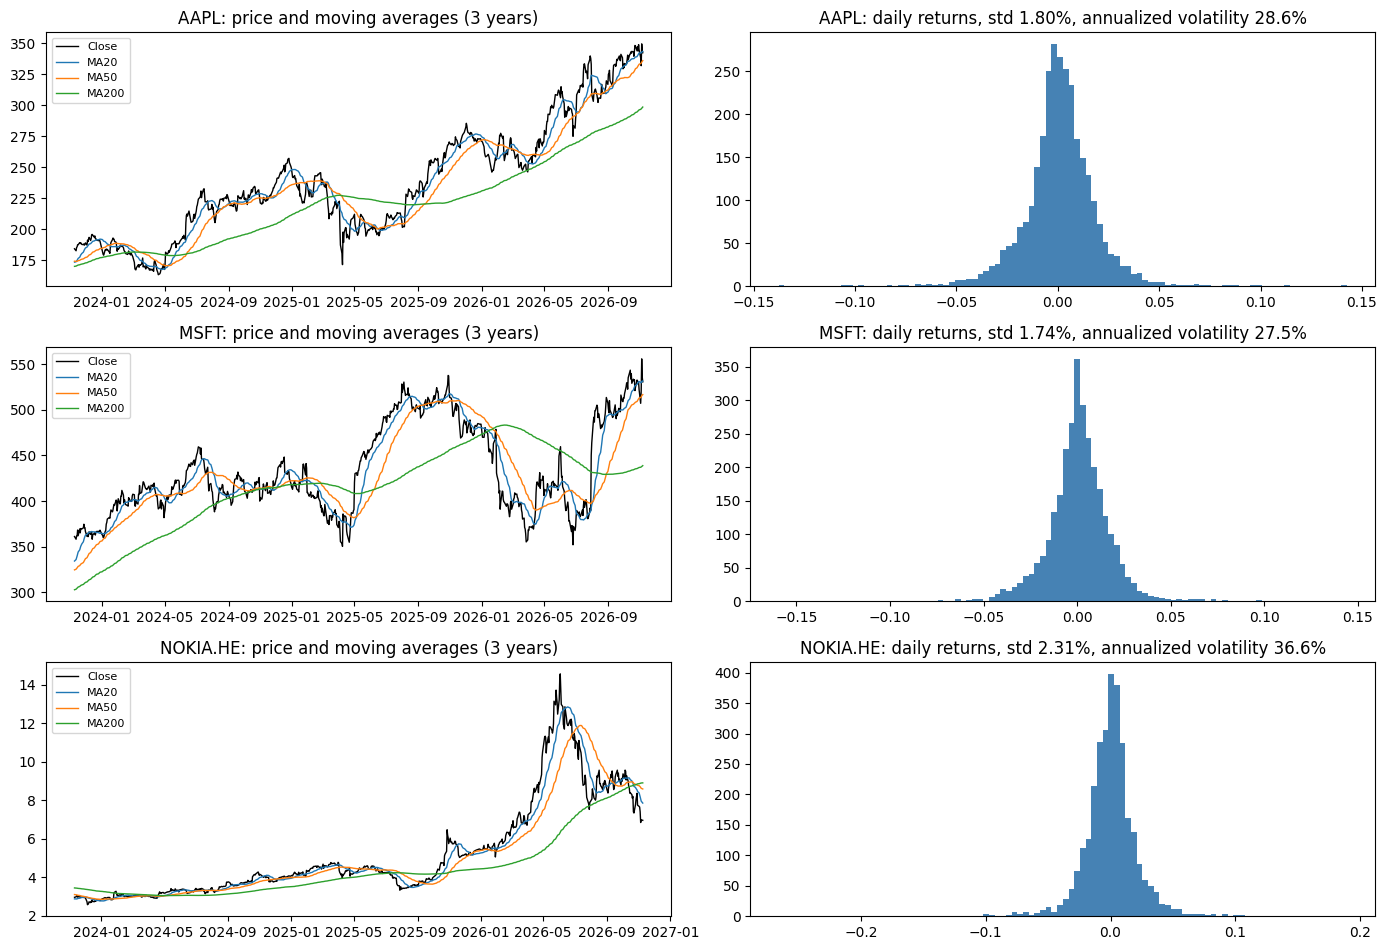

In [ ]:
# One row of charts per ticker: left = price + moving averages, right = return histogram.
fig, axes = plt.subplots(len(TICKERS), 2, figsize=(14, 3.2 * len(TICKERS)))
for (t, d), (ax1, ax2) in zip(data.items(), axes):
    # Left: last 750 trading days (~3 years) of price and three moving averages.
    ax1.plot(d["Close"].iloc[-750:], label="Close", color="black", lw=1)
    for n in (20, 50, 200):
        # .rolling(n).mean() = average of the previous n values at every point in time
        ax1.plot(d["Close"].rolling(n).mean().iloc[-750:], label=f"MA{n}", lw=1)
    ax1.set_title(f"{t}: price and moving averages (3 years)")
    ax1.legend(fontsize=8)

    # Right: daily log returns, ln(today / yesterday) ≈ percentage change.
    r = np.log(d["Close"]).diff().dropna()
    ax2.hist(r, bins=100, color="steelblue")
    ax2.set_title(f"{t}: daily returns, std {r.std():.2%}, "
                  f"annualized volatility {r.std() * np.sqrt(252):.1%}")
plt.tight_layout()
plt.show()

Returns have fat tails: large moves are more common than a normal distribution suggests, so forecasts need uncertainty intervals.

## 4. Target and Features

- **Target `y`:** log return over the next `HORIZON` days, $\ln(C_{t+H} / C_t)$.
- **Features `X`:** past returns, RSI, MACD, distance to moving averages, volatility and volume ratio.

All features use only past data to avoid look-ahead bias.

In [6]:
def rsi(close: pd.Series, n: int = 14) -> pd.Series:
    """Relative Strength Index: compares the size of recent gains to recent losses.

    RSI = 100 - 100 / (1 + average_gain / average_loss)
    -> close to 100 when the price has mostly risen, close to 0 when it has mostly fallen.
    """
    delta = close.diff()                              # daily price change
    gain = delta.clip(lower=0)                        # keep only positive changes (others -> 0)
    loss = -delta.clip(upper=0)                       # keep only negative changes, as positive numbers
    # Exponentially weighted averages (Wilder's smoothing): recent days weigh more.
    avg_gain = gain.ewm(alpha=1 / n, adjust=False).mean()
    avg_loss = loss.ewm(alpha=1 / n, adjust=False).mean()
    return 100 - 100 / (1 + avg_gain / avg_loss)


def build_features(df: pd.DataFrame, horizon: int = HORIZON):
    """Return (X, y).

    X: one row per day with features that use data up to that day only.
    y: the log return from that day to `horizon` days later (unknown for the last `horizon` days).
    """
    close = df["Close"]
    log_close = np.log(close)
    ret_1d = log_close.diff()  # daily log return

    X = pd.DataFrame(index=df.index)

    # Momentum: log return over several look-back periods.
    # log_close.diff(5) = ln(C_t) - ln(C_{t-5}) = return over the last 5 days.
    for lag in (1, 2, 5, 10, 20):
        X[f"return_{lag}d"] = log_close.diff(lag)

    # Oscillator: RSI over 14 days.
    X["rsi_14"] = rsi(close)

    # MACD = fast EMA (12 days) - slow EMA (26 days). Divided by price so that the value is
    # comparable between a 7 EUR stock and a 500 USD stock.
    ema_fast = close.ewm(span=12, adjust=False).mean()
    ema_slow = close.ewm(span=26, adjust=False).mean()
    macd = (ema_fast - ema_slow) / close
    X["macd"] = macd
    # MACD minus its own 9-day average: positive when the trend is strengthening.
    X["macd_signal"] = macd - macd.ewm(span=9, adjust=False).mean()

    # Distance from moving averages, e.g. 0.05 = price is 5% above its 50-day average.
    for n in (20, 50, 200):
        X[f"dist_ma{n}"] = close / close.rolling(n).mean() - 1

    # Volatility features.
    X["volatility_20d"] = ret_1d.rolling(20).std()
    X["volatility_ratio"] = ret_1d.rolling(5).std() / ret_1d.rolling(60).std()

    # Volume relative to normal. log() makes "2x normal" and "0.5x normal" symmetric (+0.69 / -0.69).
    X["volume_ratio"] = np.log(df["Volume"] / df["Volume"].rolling(20).mean())

    # Division by zero (e.g. zero volume) produces infinity -> treat it as missing.
    X = X.replace([np.inf, -np.inf], np.nan)

    # Target: shift(-horizon) moves future values back to day t, so
    # y[t] = ln(C[t + horizon]) - ln(C[t]). The last `horizon` rows become NaN (future unknown).
    y = log_close.shift(-horizon) - log_close
    return X, y


# Example: features for the first ticker. The first ~200 rows contain NaN because
# MA200 needs 200 days of history, so dropna() shows only complete rows.
X_example, y_example = build_features(data[TICKERS[0]])
X_example.dropna().tail()

,return_1d,return_2d,return_5d,return_10d,return_20d,rsi_14,macd,macd_signal,dist_ma20,dist_ma50,dist_ma200,volatility_20d,volatility_ratio,volume_ratio
Date,,,,,,,,,,,,,,
2026-11-02,-0.0185,-0.0308,-0.0164,-0.0136,0.0162,47.8766,0.0089,-0.0021,-0.0118,0.0141,0.1404,0.0102,1.1841,0.4347
2026-11-03,-0.0192,-0.0376,-0.0448,-0.0226,-0.0052,41.7045,0.0057,-0.0043,-0.0303,-0.0064,0.1173,0.0111,1.1275,0.3714
2026-11-04,0.0517,0.0325,0.0164,0.0159,0.0374,57.7819,0.0068,-0.0026,0.0192,0.0438,0.1745,0.0160,2.2055,0.6598
2026-11-05,-0.0154,0.0363,-0.0137,-0.0117,0.0110,53.0079,0.0067,-0.0021,0.0031,0.0260,0.1547,0.0163,2.1984,0.4479
2026-11-06,-0.0052,-0.0206,-0.0066,-0.0155,0.0169,51.4643,0.0060,-0.0022,-0.0030,0.0189,0.1468,0.0161,2.1708,-0.0861


## 5. Models

- **ARIMA:** statistical model on the price series alone; orders (p, q) chosen by AIC. Gives an interval from its error variance.
- **Gradient Boosting:** decision trees on the features, with conservative hyperparameters. Quantile regression (10th / 90th percentile) gives the 80% interval.

In [7]:
# -------------------------------------------------------------------------------------
# Model 1: ARIMA
# -------------------------------------------------------------------------------------
def select_arima_order(log_close: np.ndarray, max_p: int = 2, max_q: int = 2) -> tuple:
    """Try every (p, 1, q) with p <= max_p and q <= max_q; return the order with the lowest AIC."""
    best_aic, best_order = np.inf, (1, 1, 0)  # fallback if every fit fails
    for p in range(max_p + 1):
        for q in range(max_q + 1):
            try:
                res = ARIMA(log_close, order=(p, 1, q), trend="t").fit()
            except Exception:
                continue  # some combinations fail to converge; just skip them
            if res.aic < best_aic:
                best_aic, best_order = res.aic, (p, 1, q)
    return best_order


def fit_arima(log_close: np.ndarray, order: tuple):
    """Estimate ARIMA parameters on the given log-price series."""
    return ARIMA(log_close, order=order, trend="t").fit()


def arima_forecast(res, last_log_close: float, horizon: int = HORIZON, alpha: float = ALPHA):
    """Return (forecast, lower, upper) of the cumulative log return `horizon` days ahead.

    ARIMA forecasts log *prices*. Subtracting today's log price turns them into log *returns*,
    so that the output is directly comparable with the Gradient Boosting model.
    """
    fc = res.get_forecast(steps=horizon)       # forecasts for days t+1 ... t+horizon
    mean = fc.predicted_mean[-1]               # [-1] -> only the last step (t+horizon)
    lower, upper = fc.conf_int(alpha=alpha)[-1]  # 80% interval for the last step
    return mean - last_log_close, lower - last_log_close, upper - last_log_close


# -------------------------------------------------------------------------------------
# Model 2: Gradient Boosting
# -------------------------------------------------------------------------------------
GBM_PARAMS = dict(
    max_iter=300,           # number of trees
    learning_rate=0.03,     # how much each tree is allowed to change the prediction
    max_depth=3,            # maximum depth of each tree (small = simple rules)
    min_samples_leaf=40,    # every leaf (final rule) must contain at least 40 training days
    l2_regularization=1.0,  # penalty that discourages extreme leaf values
    random_state=0,         # makes results reproducible
)


def fit_gbm(X: pd.DataFrame, y: pd.Series, alpha: float = ALPHA) -> dict:
    """Train three models: the expected return and the lower/upper quantiles."""
    return {
        # Expected value: minimizes the squared error.
        "forecast": HistGradientBoostingRegressor(loss="squared_error", **GBM_PARAMS).fit(X, y),
        # 10th percentile (alpha / 2 = 0.1): lower edge of the 80% interval.
        "lower": HistGradientBoostingRegressor(loss="quantile", quantile=alpha / 2, **GBM_PARAMS).fit(X, y),
        # 90th percentile (1 - alpha / 2 = 0.9): upper edge of the 80% interval.
        "upper": HistGradientBoostingRegressor(loss="quantile", quantile=1 - alpha / 2, **GBM_PARAMS).fit(X, y),
    }


def gbm_forecast(models: dict, X: pd.DataFrame) -> pd.DataFrame:
    """Predict with all three models. Returns columns: forecast, lower, upper."""
    out = pd.DataFrame({name: m.predict(X) for name, m in models.items()}, index=X.index)
    # The three models are trained independently, so occasionally the "lower" prediction ends up
    # above the point forecast (quantile crossing). Fix it so that lower <= forecast <= upper.
    out["lower"] = out[["lower", "forecast"]].min(axis=1)
    out["upper"] = out[["upper", "forecast"]].max(axis=1)
    return out

## 6. Walk-Forward Backtest

Simulates real use: the test period is split into blocks, models are trained at the start of each block with data available on that day, then forecast daily within the block. Training rows are cut so that no future targets leak in.

In [8]:
def backtest(df: pd.DataFrame, n_test: int = N_TEST, horizon: int = HORIZON,
             refit_every: int = REFIT_EVERY, arima_window: int = ARIMA_WINDOW) -> pd.DataFrame:
    """Walk-forward backtest. Returns one row per forecast day with forecasts and the actual outcome."""
    X, y = build_features(df, horizon)
    close = df["Close"].to_numpy()
    log_close = np.log(close)

    # Positions (row numbers) of the test period.
    last = len(df) - horizon - 1      # last day whose actual outcome is already known
    first = last - n_test + 1         # first forecast day of the backtest

    # Select the ARIMA order once, using only data available before the test period.
    order = select_arima_order(log_close[first - arima_window + 1: first + 1])

    rows = []
    # Loop over blocks: b = first day of each block.
    for b in range(first, last + 1, refit_every):
        block = range(b, min(b + refit_every, last + 1))  # the days forecast with this training

        # --- GBM ----------------------------------------------------------------------
        # Training rows: only days s whose target is known on day b (s + horizon <= b).
        X_train, y_train = X.iloc[: b - horizon + 1], y.iloc[: b - horizon + 1]
        # Drop rows with missing values (e.g. the first 200 days, before MA200 exists).
        mask = y_train.notna() & X_train.notna().all(axis=1)
        gbm_models = fit_gbm(X_train[mask], y_train[mask])
        # Predict every day of the block at once (features for those days are known on each day).
        g = gbm_forecast(gbm_models, X.iloc[block.start: block.stop])

        # --- ARIMA --------------------------------------------------------------------
        # Fit once at the start of the block on the most recent `arima_window` log prices.
        res_block = fit_arima(log_close[b - arima_window + 1: b + 1], order)
        for k, i in enumerate(block):  # k = 0, 1, 2 ... (day within block), i = row number
            # On later days of the block, add the newly observed prices without re-estimating
            # parameters. (`extend` would be faster, but it resets the trend's time index,
            # which produces a wrong drift; `append` handles it correctly.)
            res = res_block if k == 0 else res_block.append(log_close[b + 1: i + 1])
            a, a_lower, a_upper = arima_forecast(res, log_close[i], horizon)

            # Store everything for this forecast day. All forecasts are log returns.
            rows.append({
                "date": df.index[i],          # day the forecast was made
                "price": close[i],            # closing price on that day
                "actual": y.iloc[i],          # actual log return over the next `horizon` days
                "naive": 0.0,                 # baseline: "the price will not change"
                "arima": a, "arima_lower": a_lower, "arima_upper": a_upper,
                "gbm": g["forecast"].iloc[k], "gbm_lower": g["lower"].iloc[k], "gbm_upper": g["upper"].iloc[k],
            })

    result = pd.DataFrame(rows).set_index("date")
    result.attrs["arima_order"] = order  # keep the selected order for reporting
    return result


# Run the backtest for every ticker and time it.
results = {}
for t in TICKERS:
    t0 = time.perf_counter()
    results[t] = backtest(data[t])
    print(f"{t:10s} ARIMA{results[t].attrs['arima_order']}  "
          f"{len(results[t])} forecasts  {time.perf_counter() - t0:.1f} s")

AAPL       ARIMA(0, 1, 0)  500 forecasts  24.6 s


MSFT       ARIMA(0, 1, 2)  500 forecasts  23.6 s


NOKIA.HE   ARIMA(0, 1, 0)  500 forecasts  22.8 s


One row per forecast (log returns) next to the actual outcome:

In [9]:
results[TICKERS[0]].tail()

,price,actual,naive,arima,arima_lower,arima_upper,gbm,gbm_lower,gbm_upper
date,,,,,,,,,
2026-10-26,343.9100,-0.0164,0.0000,0.0042,-0.0440,0.0524,-0.0044,-0.0423,0.0363
2026-10-27,347.1000,-0.0448,0.0000,0.0042,-0.0440,0.0524,0.0055,-0.0332,0.0347
2026-10-28,343.8300,0.0164,0.0000,0.0042,-0.0440,0.0524,0.0058,-0.0338,0.0418
2026-10-29,348.9100,-0.0137,0.0000,0.0042,-0.0440,0.0524,0.0038,-0.0343,0.0338
2026-10-30,344.6300,-0.0066,0.0000,0.0042,-0.0440,0.0524,0.0143,-0.0350,0.0498


## 7. Results

Compares models to a naive baseline (return = 0) using MAE, RMSE, skill vs. naive, direction accuracy and 80% interval coverage.

In [10]:
def evaluate(r: pd.DataFrame) -> pd.DataFrame:
    """Compute the metrics for every model from a backtest result table."""
    actual = r["actual"]
    mae_naive = (r["naive"] - actual).abs().mean()  # reference error for the skill score

    rows = {}
    for model in ("naive", "arima", "gbm"):
        error = r[model] - actual
        mae = error.abs().mean()

        # Direction accuracy. The naive forecast is exactly 0 (no direction), so for it we use
        # the "always up" strategy: the share of periods in which the stock actually rose.
        if model == "naive":
            direction = (actual > 0).mean()
        else:
            direction = (np.sign(r[model]) == np.sign(actual)).mean()

        # Interval coverage: share of actual values between lower and upper (naive has no interval).
        if f"{model}_lower" in r:
            inside = (actual >= r[f"{model}_lower"]) & (actual <= r[f"{model}_upper"])
            coverage = inside.mean()
        else:
            coverage = np.nan

        rows[model] = {
            "MAE": mae,
            "RMSE": np.sqrt((error ** 2).mean()),
            "Skill vs. naive": 1 - mae / mae_naive,
            "Direction accuracy": direction,
            "Interval coverage": coverage,
        }
    return pd.DataFrame(rows).T  # .T = transpose, so that models are rows and metrics are columns


# Combine the metrics of all tickers into one table with a two-level index (Ticker, Model).
summary = pd.concat({t: evaluate(r) for t, r in results.items()}, names=["Ticker", "Model"])
summary

MAE   RMSE  Skill vs. naive  Direction accuracy  \
Ticker   Model                                                      
AAPL     naive 0.0311 0.0419           0.0000              0.5700   
         arima 0.0308 0.0417           0.0080              0.5700   
         gbm   0.0302 0.0416           0.0268              0.5760   
MSFT     naive 0.0294 0.0425           0.0000              0.5560   
         arima 0.0294 0.0427          -0.0011              0.5360   
         gbm   0.0308 0.0438          -0.0474              0.5640   
NOKIA.HE naive 0.0468 0.0664           0.0000              0.5520   
         arima 0.0471 0.0667          -0.0062              0.4560   
         gbm   0.0509 0.0711          -0.0859              0.5060   

                Interval coverage  
Ticker   Model                     
AAPL     naive                NaN  
         arima             0.8020  
         gbm               0.7240  
MSFT     naive                NaN  
         arima             0.8100  
         gbm               0.7000  
NOKIA.HE naive                NaN  
         arima             0.7140  
         gbm               0.6640

### Visual check

Forecasts converted back to prices vs. the actual price, with 80% intervals shaded.

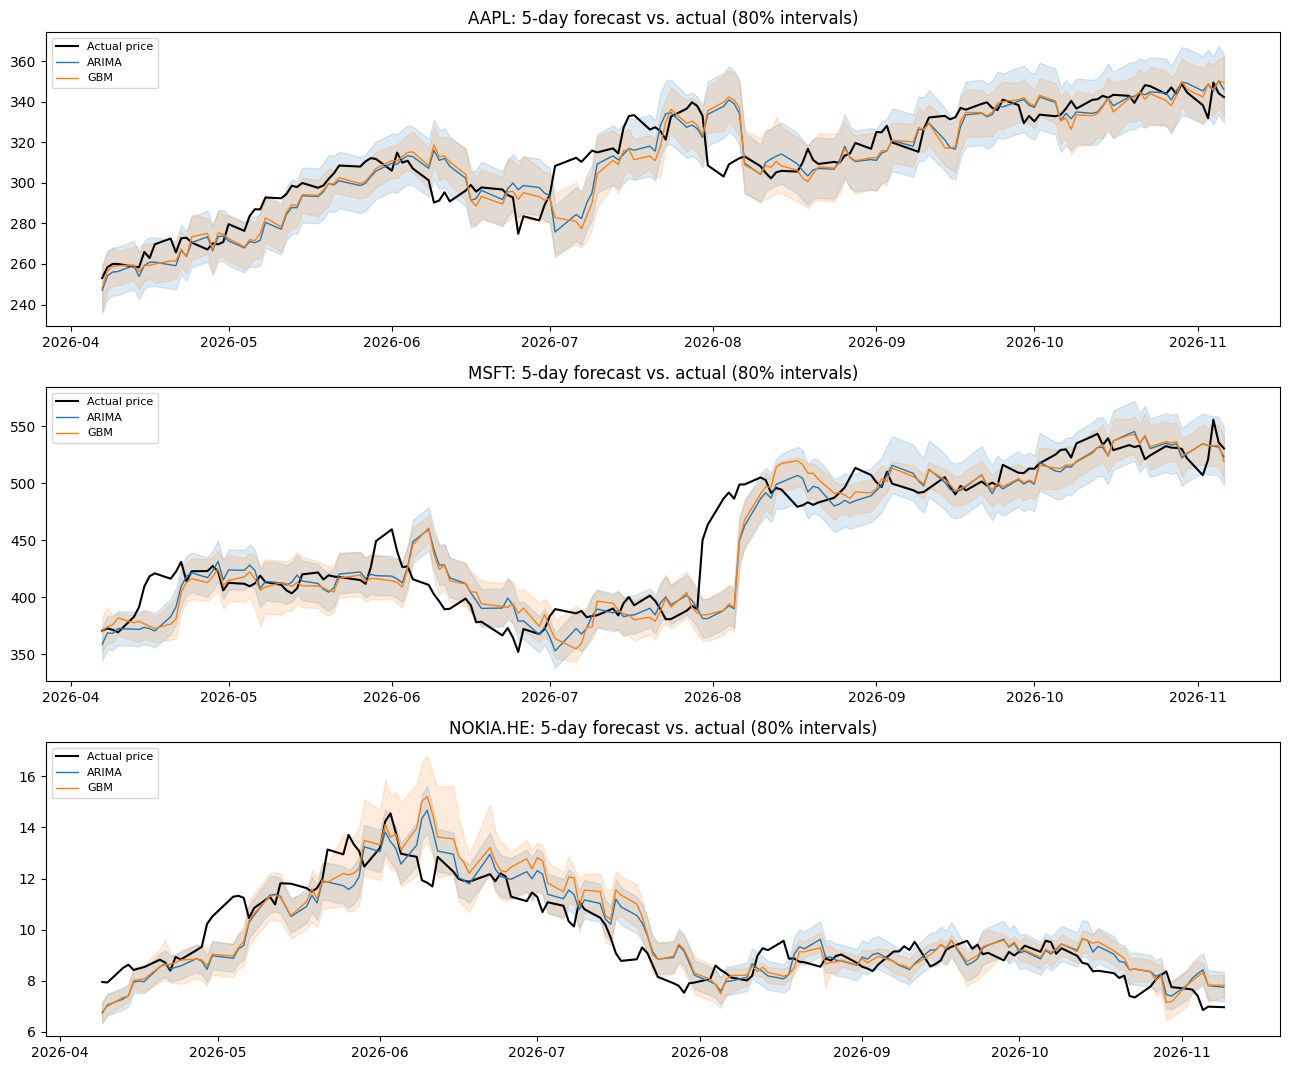

In [11]:
fig, axes = plt.subplots(len(TICKERS), 1, figsize=(13, 3.6 * len(TICKERS)))
SHOW_LAST = 150  # only the last 150 forecasts, otherwise the chart becomes unreadable

for ax, (t, r) in zip(np.atleast_1d(axes), results.items()):
    r = r.iloc[-SHOW_LAST:]
    # Each forecast is about the date HORIZON trading days after it was made.
    # get_indexer finds the row number of each forecast date, + HORIZON gives the target row.
    target_dates = data[t].index[data[t].index.get_indexer(r.index) + HORIZON]

    # Convert log returns back to prices: price_target = price_today * exp(log_return).
    ax.plot(target_dates, r["price"] * np.exp(r["actual"]), color="black", lw=1.5, label="Actual price")
    for model, color in (("arima", "tab:blue"), ("gbm", "tab:orange")):
        ax.plot(target_dates, r["price"] * np.exp(r[model]), color=color, lw=1, label=model.upper())
        ax.fill_between(target_dates,
                        r["price"] * np.exp(r[f"{model}_lower"]),
                        r["price"] * np.exp(r[f"{model}_upper"]),
                        color=color, alpha=0.15)  # alpha = transparency of the band
    ax.set_title(f"{t}: {HORIZON}-day forecast vs. actual (80% intervals)")
    ax.legend(fontsize=8, loc="upper left")
plt.tight_layout()
plt.show()

## 8. Latest Forecast

Trains both models on all data and forecasts the next `HORIZON` days. Future dates are approximated with business days.

In [12]:
def latest_forecast(df: pd.DataFrame, horizon: int = HORIZON, alpha: float = ALPHA) -> dict:
    """Train both models on all data and forecast `horizon` trading days into the future."""
    # --- GBM: train on all rows with a known target, predict from the latest row --------
    X, y = build_features(df, horizon)
    mask = y.notna() & X.notna().all(axis=1)
    gbm_models = fit_gbm(X[mask], y[mask], alpha)
    g = gbm_forecast(gbm_models, X.iloc[[-1]]).iloc[0]  # X.iloc[[-1]] = today's features only

    # --- ARIMA: fit on the latest window and forecast the whole path -------------------
    log_close = np.log(df["Close"].to_numpy())[-ARIMA_WINDOW:]
    order = select_arima_order(log_close)
    fc = fit_arima(log_close, order).get_forecast(steps=horizon)
    ci = fc.conf_int(alpha=alpha)  # array with columns [lower, upper] for every future day

    price = df["Close"].iloc[-1]
    # Approximate future trading days: business days after the last date (holidays ignored).
    dates = pd.bdate_range(df.index[-1] + pd.Timedelta(days=1), periods=horizon)
    return {
        "price": price,
        "date": df.index[-1],
        "order": order,
        # ARIMA forecasts log prices, so exp() gives prices directly.
        "arima_path": pd.DataFrame({"forecast": np.exp(fc.predicted_mean),
                                    "lower": np.exp(ci[:, 0]),
                                    "upper": np.exp(ci[:, 1])}, index=dates),
        # GBM forecasts a log return, so: price * exp(return).
        "gbm": {name: price * np.exp(value) for name, value in g.items()},
        "gbm_date": dates[-1],
    }


forecasts = {t: latest_forecast(data[t]) for t in TICKERS}

# Build a readable summary table: one row per ticker.
table = pd.DataFrame({
    t: {
        "Last date": f["date"].date(),
        "Last price": round(f["price"], 2),
        "ARIMA order": str(f["order"]),
        "ARIMA forecast": round(f["arima_path"]["forecast"].iloc[-1], 2),
        "ARIMA 80% interval": f"{f['arima_path']['lower'].iloc[-1]:.2f} – {f['arima_path']['upper'].iloc[-1]:.2f}",
        "GBM forecast": round(f["gbm"]["forecast"], 2),
        "GBM 80% interval": f"{f['gbm']['lower']:.2f} – {f['gbm']['upper']:.2f}",
        "ARIMA change": f"{f['arima_path']['forecast'].iloc[-1] / f['price'] - 1:+.2%}",
        "GBM change": f"{f['gbm']['forecast'] / f['price'] - 1:+.2%}",
    }
    for t, f in forecasts.items()
}).T
table.index.name = f"Forecast {HORIZON} trading days ahead"
table

,Last date,Last price,ARIMA order,ARIMA forecast,ARIMA 80% interval,GBM forecast,GBM 80% interval,ARIMA change,GBM change
Forecast 5 trading days ahead,,,,,,,,,
AAPL,2026-11-06,342.3700,"(0, 1, 2)",343.1700,326.04 – 361.20,342.4600,322.18 – 357.14,+0.23%,+0.03%
MSFT,2026-11-06,530.6100,"(0, 1, 0)",531.9600,507.28 – 557.84,535.3600,509.43 – 557.42,+0.25%,+0.90%
NOKIA.HE,2026-11-09,6.9600,"(0, 1, 0)",7.0000,6.48 – 7.56,6.9700,6.43 – 7.50,+0.57%,+0.16%


The interval matters more than the point forecast. Blue cone = ARIMA path, orange marker = GBM forecast.

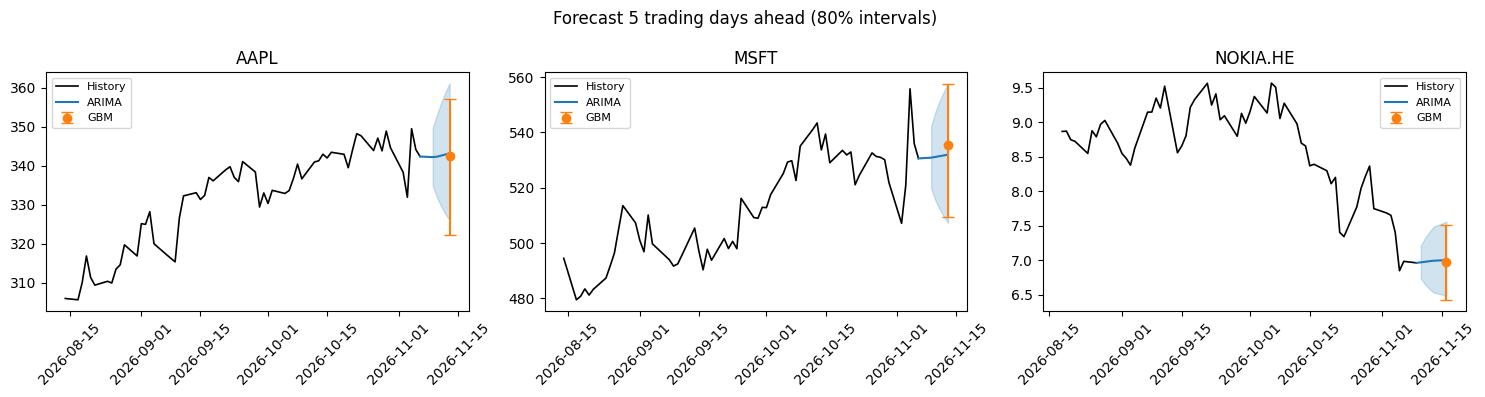

In [13]:
fig, axes = plt.subplots(1, len(TICKERS), figsize=(5 * len(TICKERS), 4))
for ax, (t, f) in zip(np.atleast_1d(axes), forecasts.items()):
    # Last 60 trading days of history.
    ax.plot(data[t]["Close"].iloc[-60:], color="black", lw=1.2, label="History")

    # ARIMA path: prepend today's price so the line starts from the last real price.
    path = f["arima_path"]
    start = pd.Series([f["price"]], index=[f["date"]])
    ax.plot(pd.concat([start, path["forecast"]]), color="tab:blue", label="ARIMA")
    ax.fill_between(path.index, path["lower"], path["upper"], color="tab:blue", alpha=0.2)

    # GBM: a single point with an asymmetric error bar (distance down to lower, up to upper).
    gb = f["gbm"]
    ax.errorbar([f["gbm_date"]], [gb["forecast"]],
                yerr=[[gb["forecast"] - gb["lower"]], [gb["upper"] - gb["forecast"]]],
                fmt="o", color="tab:orange", capsize=4, label="GBM")
    ax.set_title(t)
    ax.tick_params(axis="x", rotation=45)
    ax.legend(fontsize=8)
plt.suptitle(f"Forecast {HORIZON} trading days ahead (80% intervals)")
plt.tight_layout()
plt.show()

## 9. Conclusions and Next Steps

- Short-term prices are close to a random walk, so beating the naive baseline is hard.
- ARIMA often picks (0, 1, 0), i.e. random walk + drift.
- GBM intervals are too narrow and need calibration.

**Next:** Python package + tests, more models, FastAPI backend, Android app, AI explanation layer.